# COX-2 model training

Run the cells top to bottom. Only **cell 1** needs editing.

**What happens:** the raw data is cleaned and featurised, the model is tuned and
trained twice (random split and scaffold split), it is checked against a
similarity baseline, and the final model is saved.

**Runtime:** roughly 30-50 minutes with the default settings. The GPU is not
used; scikit-learn random forests run on CPU. More cores means faster.

**Needs:** `rdkit scikit-learn optuna joblib pandas numpy matplotlib scipy`

## 1. Settings — edit this cell

In [1]:
# Column names in the raw CSV (see cell 2 to print them)
SMILES_COL = "Smiles"
LABEL_COL = "Activity"

# Extra descriptor columns from the raw file to use as features.
# None  -> use every numeric column that is not SMILES or the label
# []    -> use only the features computed from SMILES
# [...] -> use exactly these
KEEP_COLS = None

# How long the hyperparameter search may run, PER split mode.
# Stops at whichever limit is reached first. "both" runs it twice.
N_TRIALS = 30
TIMEOUT_MIN = 45

# "both" = random + scaffold (recommended: the gap is a result in itself)
SPLIT_MODE = "both"

# Explainability
TARGET_CLASS = 1  # class to explain, 1 = active
ONLY_IN_DOMAIN = True  # explain only test molecules similar to the training data
SHAP_MAX_MOLECULES = 500  # TreeSHAP on a large forest is slow, so the test set is subsampled

## 2. Load the raw data and check the columns

In [2]:
import ethnohack.cox_model.cox_preprocess as prep
import ethnohack.cox_model.cox_train as train

raw = prep.load_raw()
print(f"{len(raw)} rows, {len(raw.columns)} columns\n")
print(raw.columns.tolist())
raw.head(3)

/home/jenna/workspace/ethnohack/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


4520 rows, 4 columns

['Molecule ChEMBL ID', 'Smiles', 'Activity', 'scaffold']


,Molecule ChEMBL ID,Smiles,Activity,scaffold
0,CHEMBL501208,CS(=O)(=O)c1ccc(-c2[nH]c3ccccc3c2-c2ccc(F)cc2)cc1,1,c1ccc(-c2[nH]c3ccccc3c2-c2ccccc2)cc1
1,CHEMBL499069,COc1ccc(-c2c(-c3ccc(S(C)(=O)=O)cc3)[nH]c3ccccc...,1,c1ccc(-c2[nH]c3ccccc3c2-c2ccccc2)cc1
2,CHEMBL525247,Cc1ccc2[nH]c(-c3ccc(S(N)(=O)=O)cc3)c(-c3ccccc3...,1,c1ccc(-c2[nH]c3ccccc3c2-c2ccccc2)cc1


**Stop here if** `SMILES_COL` or `LABEL_COL` are not in that list. Fix cell 1 first.

## 3. Preprocessing

Cleans the data, computes Murcko scaffolds (the ring core of each molecule,
used to group analogues), builds the feature table and writes it to disk.

In [3]:
keep = KEEP_COLS
if keep is None:
    keep = [c for c in raw.columns if c not in (SMILES_COL, LABEL_COL)]

data = prep.build_dataset(
    smiles_col=SMILES_COL,
    label_col=LABEL_COL,
    keep_cols=keep,
)

cols = prep.feature_columns(data)
extra = [c for c in cols if not c.startswith("fp_")]
print(f"\n{len(cols)} feature columns, of which {len(extra)} are not fingerprint bits")
print(extra[:30])

Unparsable SMILES removed: 0
Compounds: 4520 | actives: 2492 (55.1%)
Unique scaffolds: 1336
Feature columns: 2048  (mode: ecfp)
Saved: /home/jenna/workspace/ethnohack/datasets/cox2_prepared.csv

2048 feature columns, of which 0 are not fingerprint bits
[]


### Can these features be computed for new molecules?

Important for later: the plant compounds are not in the raw file, so every
feature must be computable from a SMILES string alone. Columns listed as
missing below exist only in the training table and will break prediction.

In [4]:
probe = prep.compute_rdkit_features(["CC(=O)Oc1ccccc1C(=O)O"])  # aspirin
missing = sorted(set(cols) - set(probe.columns))
print("Cannot be computed for new molecules:", missing or "none")

Cannot be computed for new molecules: none


## 4. Train

**Random split:** close analogues land in both train and test, so the model can
recognise the compound series instead of the chemistry. Scores look good.

**Scaffold split:** molecules sharing a ring core stay on one side. Closer to
the real task (unseen plant metabolites). Lower, but honest. **Report this one.**

This is the long cell.

In [5]:
results = train.run_models(
    data, SPLIT_MODE, n_trials=N_TRIALS, timeout_min=TIMEOUT_MIN
)
best = results[-1]  # scaffold run when SPLIT_MODE == "both"


SPLIT: RANDOM
train: 3616 | test: 904 | features: 2048


Best trial: 24. Best value: 0.881506: 100%|██████████| 30/30 [06:43<00:00, 13.44s/it, 403.21/2700 seconds]


Best CV PR-AUC: 0.882 | params: {'n_estimators': 300, 'max_depth': 36, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'criterion': 'entropy', 'class_weight': 'balanced'}

Prevalence (random-guess PR-AUC): 0.552
pr_auc    : 0.905
roc_auc   : 0.893
mcc       : 0.639
precision : 0.830
recall    : 0.852
f1        : 0.841

SPLIT: SCAFFOLD
train: 3610 | test: 910 | features: 2048
scaffold overlap (must be 0): 0


Best trial: 18. Best value: 0.788418: 100%|██████████| 30/30 [06:40<00:00, 13.35s/it, 400.61/2700 seconds]


Best CV PR-AUC: 0.788 | params: {'n_estimators': 600, 'max_depth': 35, 'min_samples_leaf': 1, 'max_features': 'log2', 'criterion': 'entropy', 'class_weight': 'balanced'}

Prevalence (random-guess PR-AUC): 0.552
pr_auc    : 0.809
roc_auc   : 0.774
mcc       : 0.391
precision : 0.721
recall    : 0.745
f1        : 0.733


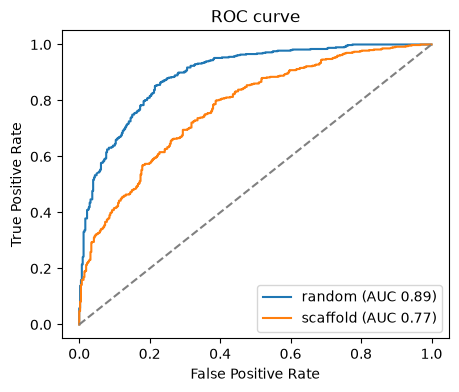

In [6]:
train.plot_roc(results)

## 5. Sanity checks

These decide what you can claim about the model. Note the numbers down.

### 5a. Is the model better than a similarity search?

Baseline: score each test compound by how similar it is to the nearest known
active. If the model barely beats this, it mostly learned "looks like a known
active" rather than anything about the chemistry. Worth reporting either way.

In [7]:
sim = train.similarity_baseline(best)
combo = train.combined_baseline(best, sim)

Similarity baseline  ROC-AUC: 0.76 | PR-AUC: 0.792
Model                ROC-AUC: 0.774 | PR-AUC: 0.809
Combined ROC-AUC: 0.785 | PR-AUC: 0.82


### 5b. Where does the model actually work?

Test AUC split by structural similarity to the training set. The lowest bin
predicts how the model will behave on unfamiliar plant metabolites, which is
the number that matters for the project.

In [8]:
bins = train.reliability_bins(best)

max Tanimoto to train   n   AUC
       (0.196, 0.491] 228 0.641
        (0.491, 0.61] 229 0.664
        (0.61, 0.724] 225 0.739
         (0.724, 1.0] 228 0.867


## 6. Save

Saves the model together with the feature settings and column order, plus the
training SMILES (needed for the reliability flag at prediction time).

`tune_cutoff=True` picks the 0/1 threshold by cross-validation on the training
data instead of defaulting to 0.5. The test set stays untouched.

In [9]:
train.save_model(best, tune_cutoff=True)

Tuned cutoff: 0.40 (CV MCC 0.394)
Saved: /home/jenna/workspace/ethnohack/src/ethnohack/cox_model/cox_model.joblib (cutoff 0.40, 2048 features)


## 7. Check the saved model loads

In [10]:
import ethnohack.cox_model.cox_model_api as cox

cox.reset_cache()
cox.model_info()

cox.predict(["CC(=O)Oc1ccccc1C(=O)O", "CC(C)Cc1ccc(cc1)C(C)C(=O)O"])  # aspirin, ibuprofen

feature mode : ecfp (2048 columns)
split        : scaffold
cutoff       : 0.40
prevalence  : 0.552
pr_auc      : 0.809
roc_auc     : 0.774
mcc         : 0.391
precision   : 0.721
recall      : 0.745
f1          : 0.733


,smiles,proba,active,max_sim_train,in_domain
0,CC(=O)Oc1ccccc1C(=O)O,0.257298,0.0,1.0,True
1,CC(C)Cc1ccc(cc1)C(C)C(=O)O,0.270820,0.0,1.0,True


---

## Reading the results

**Compare PR-AUC against the prevalence**, not against 0. Prevalence is the
share of actives, which is what random guessing already achieves.

**The probabilities are a ranking, not a verdict.** Use them to compare and
sort compounds, not to declare one active.

**Filter to `in_domain == True`** before drawing conclusions or running SHAP.
Predictions on molecules far from the training data are much less reliable.

## For the 5-LOX model

Point the constants at the 5-LOX paths and rerun this notebook unchanged.

---

## 8. Explain the model (TreeSHAP)

SHAP splits each prediction into contributions of the individual features
(fingerprint bits and any extra descriptors). Positive values push toward
active, negative toward inactive.

Uses the saved model from section 7, so the features match the training exactly.

In [22]:
import ethnohack.explainer as xai

model = cox.load_model()

# fingerprint bits must come first, extra features after (needed for bit drawing)
xai.check_feature_layout(cox.feature_names(), model, cox.load_bundle())

2048 fingerprint bits + 0 extra features


### 8a. Global view: which features drive the model

With `ONLY_IN_DOMAIN = True` only test molecules similar enough to the training
data are used, because SHAP on unfamiliar molecules explains unreliable predictions.

667 of 910 test molecules used


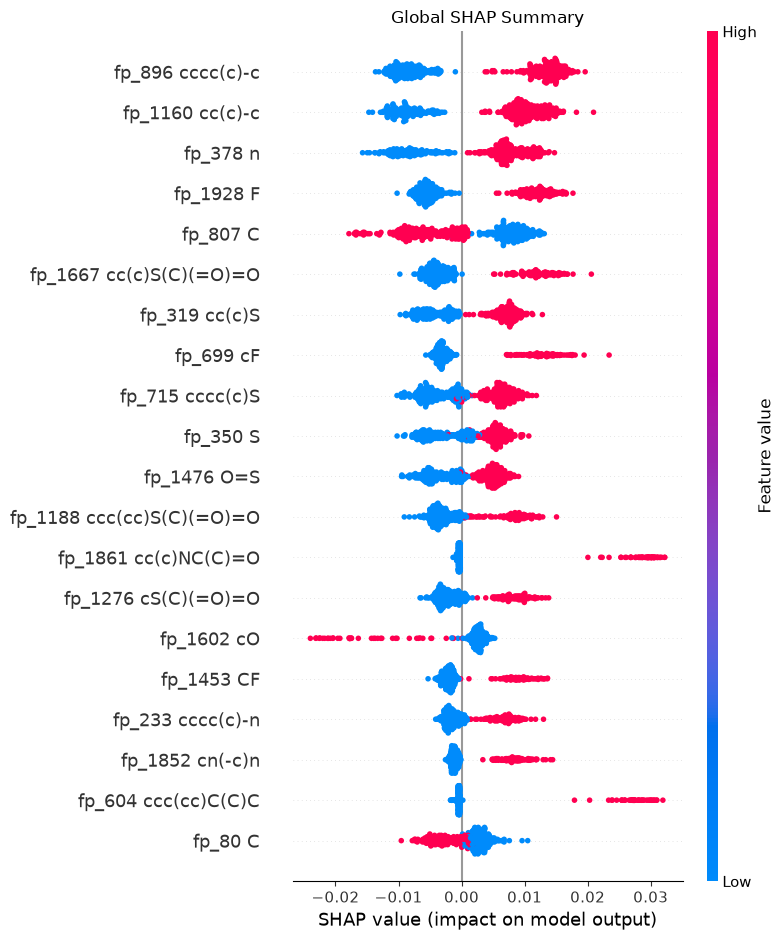

In [12]:
test_smiles = best["test_df"]["smiles"]
in_domain = cox.predict(test_smiles)["in_domain"].to_numpy(dtype=bool)
use = in_domain | (not ONLY_IN_DOMAIN)
print(f"{use.sum()} of {len(use)} test molecules used")

X_te = cox.featurize(test_smiles)[use]

# fingerprint bits get a substructure hint in their name for the plots
feature_names = xai.readable_feature_names(cox.feature_names(), test_smiles[use])

shap_matrix, X_shap = xai.global_shap(
    model, X_te, TARGET_CLASS, n_max=SHAP_MAX_MOLECULES
)
xai.plot_global_shap(shap_matrix, X_shap, feature_names)

In [13]:
top_features = xai.top_bits_table(shap_matrix, X_shap, feature_names)
top_features

,feature_index,kind,feature,mean_abs_shap,mean_shap_when_present,pushes_toward,share_of_molecules
0,896,fingerprint bit,fp_896 cccc(c)-c,0.011167,0.013613,active,0.522
1,1160,fingerprint bit,fp_1160 cc(c)-c,0.009903,0.010520,active,0.652
2,378,fingerprint bit,fp_378 n,0.008119,0.007990,active,0.688
3,1928,fingerprint bit,fp_1928 F,0.008053,0.012006,active,0.400
4,807,fingerprint bit,fp_807 C,0.006758,-0.005612,inactive,0.546
5,1667,fingerprint bit,fp_1667 cc(c)S(C)(=O)=O,0.005852,0.011923,active,0.240
6,319,fingerprint bit,fp_319 cc(c)S,0.005815,0.007120,active,0.508
7,699,fingerprint bit,fp_699 cF,0.005333,0.012694,active,0.228
8,715,fingerprint bit,fp_715 cccc(c)S,0.005035,0.006150,active,0.498
9,350,fingerprint bit,fp_350 S,0.004679,0.005538,active,0.516


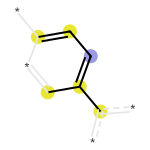

In [14]:
# most important fingerprint bit drawn as a substructure on a test molecule
top_bits = xai.top_bits_table(shap_matrix, X_shap, feature_names, n_top=1, fp_only=True)
xai.highlight_bit(top_bits["feature_index"].iloc[0], X_te, test_smiles[use])

### 8b. Local view: why single molecules get their prediction

Most confident hits and mistakes from the test set. Red = pushes toward active,
blue = pushes toward inactive. The waterfall starts at the average prediction
(base value) and ends at the model probability.

In [15]:
examples = xai.select_examples(best, mask=use)

# in_domain tells you whether each prediction can be trusted
cox.predict([smiles for smiles, _, _ in examples.values()])

,smiles,proba,active,max_sim_train,in_domain
0,Cc1c(CCC(=O)O)cccc1NC(=O)C(c1ccc(-c2cncc(C(F)(...,0.986046,1.0,1.000000,True
1,CC(=O)NCCc1cc(O)c(O)cc1C(=O)c1ccc(O)c(O)c1,0.166265,0.0,0.520000,True
2,COc1ccc(/C=C/C(=O)O[C@H]2[C@H](O[C@H]3[C@H](O)...,0.008447,0.0,0.992188,True
3,Cc1c(CCC(=O)O)cccc1NC(=O)C(c1ccc(-c2cncc(C(C)(...,0.932858,1.0,0.855072,True



##### True active (most confident) | true label: 1 | model probability: 0.986
SMILES: Cc1c(CCC(=O)O)cccc1NC(=O)C(c1ccc(-c2cncc(C(F)(F)F)c2)cc1)C1CCCC1
Base value: 0.501 | Model probability: 0.986
=== Overlaying Top 2 Present Features ===
Bit ID: 1861| SHAP: +0.028809| Active (+)
Bit ID:  604| SHAP: +0.023991| Active (+)


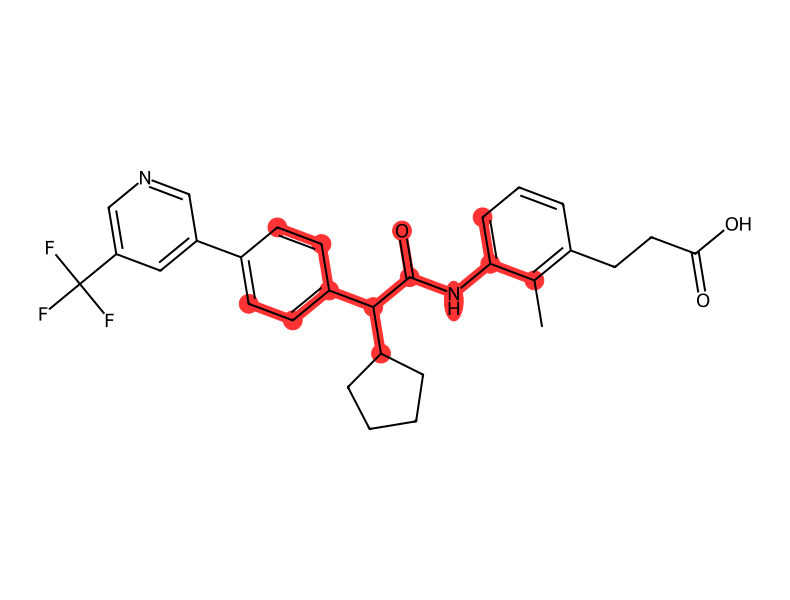

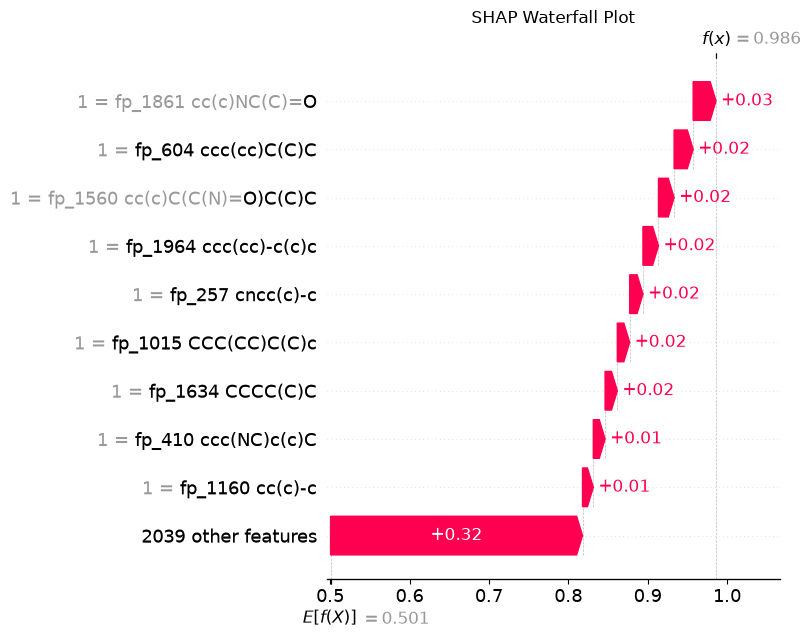


##### False negative (active predicted inactive) | true label: 1 | model probability: 0.166
SMILES: CC(=O)NCCc1cc(O)c(O)cc1C(=O)c1ccc(O)c(O)c1
Base value: 0.501 | Model probability: 0.166
=== Overlaying Top 2 Present Features ===
Bit ID:  589| SHAP: -0.029944| Inactive (-)
Bit ID:  315| SHAP: -0.022738| Inactive (-)


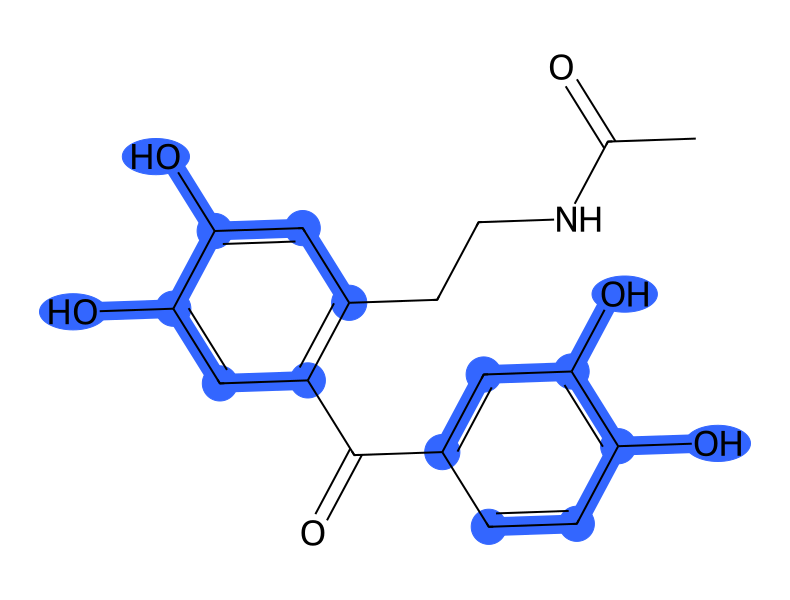

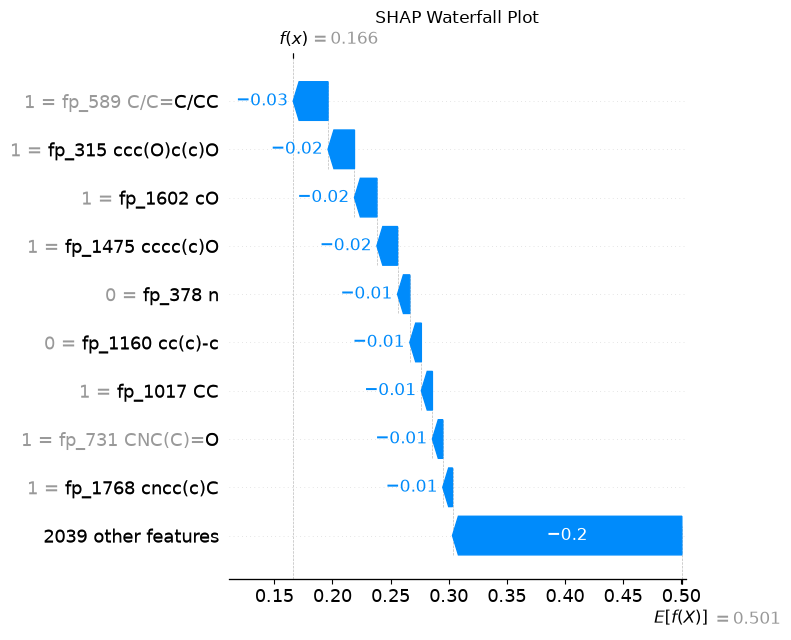


##### True inactive (most confident) | true label: 0 | model probability: 0.008
SMILES: COc1ccc(/C=C/C(=O)O[C@H]2[C@H](O[C@H]3[C@H](O)[C@@H](O)[C@H](O[C@@H]4CO[C@@H](O[C@@H]5[C@@H](O)[C@H](C)O[C@@H](O[C@H]6[C@H](O[C@H]7CC[C@@]8(C)[C@@H](CC[C@]9(C)[C@@H]8CC=C8[C@@H]%10CC(C)(C)CC[C@]%10(C(=O)O[C@@H]%10O[C@H](CO[C@@H]%11O[C@H](CO)[C@@H](O[C@@H]%12O[C@@H](C)[C@H](O)[C@@H](O)[C@H]%12O)[C@H](O)[C@H]%11O)[C@@H](O)[C@H](O)[C@H]%10O)CC[C@]89C)[C@]7(C)CO)OC[C@@H](O)[C@@H]6O)[C@@H]5O)[C@H](O)[C@@H]4O)O[C@@H]3CO)O[C@H](CO)[C@@H](O)[C@@H]2O[C@@H]2O[C@H](CO[C@@H]3O[C@@H](C)[C@H](O)[C@@H](O)[C@H]3O)[C@@H](O[C@@H]3O[C@H](CO)[C@@H](O)[C@H](O)[C@H]3O)[C@H](O)[C@H]2O)cc1O
Base value: 0.501 | Model probability: 0.008
=== Overlaying Top 2 Present Features ===
Bit ID: 1962| SHAP: -0.017318| Inactive (-)
Bit ID:  679| SHAP: -0.016043| Inactive (-)


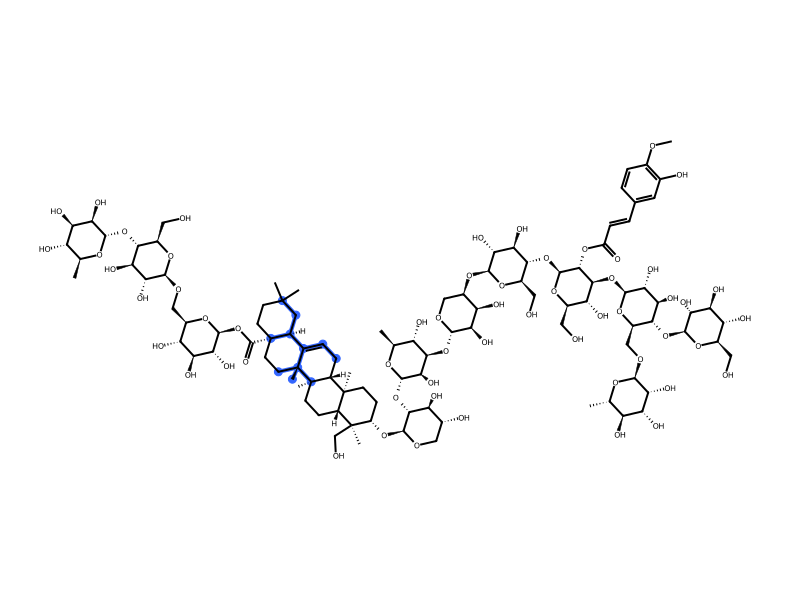

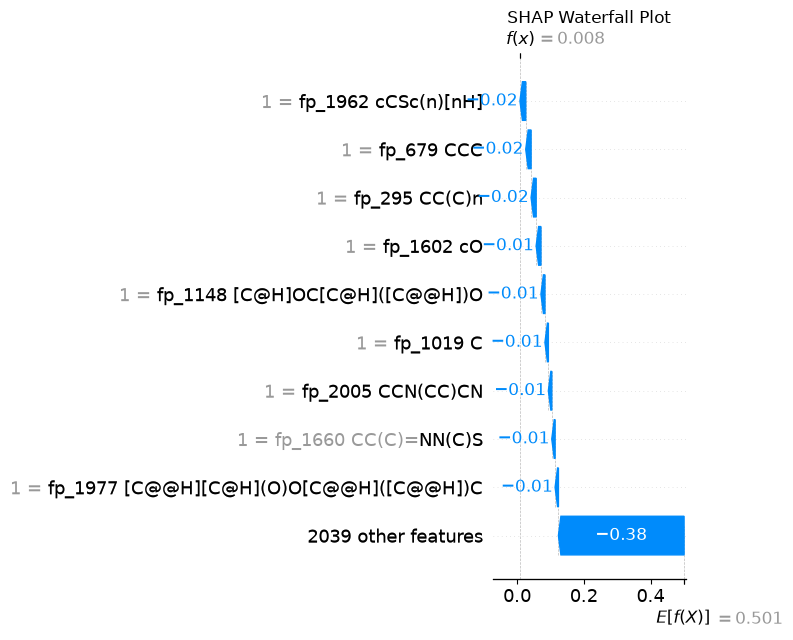


##### False positive (inactive predicted active) | true label: 0 | model probability: 0.933
SMILES: Cc1c(CCC(=O)O)cccc1NC(=O)C(c1ccc(-c2cncc(C(C)(C)O)c2)cc1)C1CCCC1
Base value: 0.501 | Model probability: 0.933
=== Overlaying Top 2 Present Features ===
Bit ID: 1861| SHAP: +0.029212| Active (+)
Bit ID:  604| SHAP: +0.026523| Active (+)


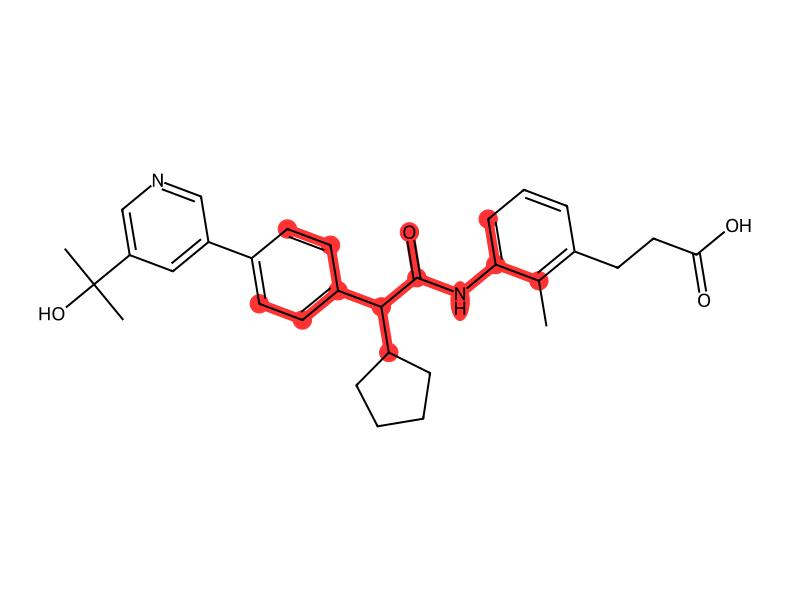

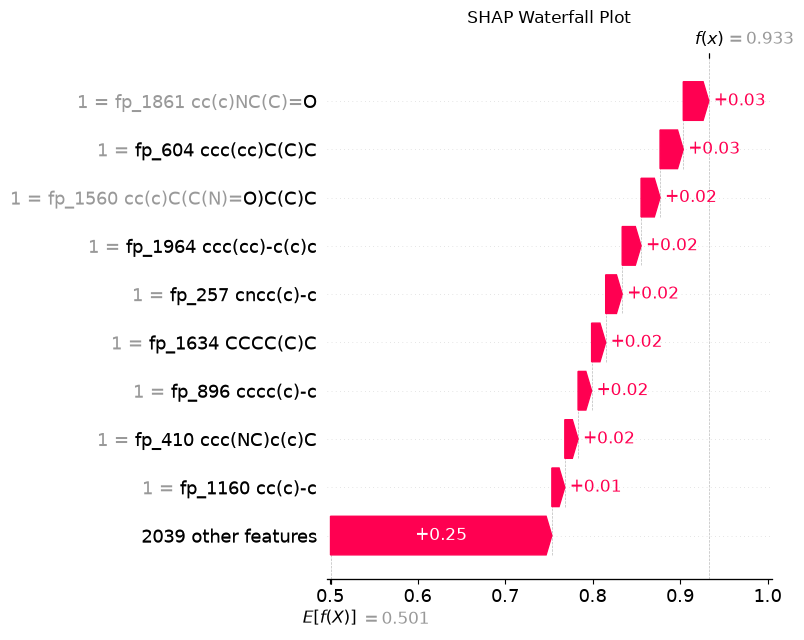

In [ ]:
for name, (smiles, proba, label) in examples.items():
    print(f"\n##### {name} | True Label: {label} | Model Probability: {proba:.3f}")
    xai.explain_molecule(
        smiles,
        model,
        target_class=TARGET_CLASS,
        feature_names=feature_names,
        featurizer=cox.featurize,
    )

## 9. Screen COCONUT natural products

Scores natural products from COCONUT with the saved model, checks whether each
one is similar enough to the training data to be trusted, ranks them and
explains the top hits.

**Before you start:** download the COCONUT CSV from
https://coconut.naturalproducts.net/download and put it at `COCONUT_CSV` in
`constants.py`. Sections 6 and 7 must have run, because this uses the saved model.

In [17]:
import importlib
import ethnohack.constants
import ethnohack.coconut as coco
importlib.reload(ethnohack.constants)
from ethnohack.constants import PLANT_GENERA_FILE

In [9]:
# COCONUT screening
COCONUT_SMILES_COL = "canonical_smiles"
COCONUT_ID_COL = "identifier"
COCONUT_NAME_COL = "name"
COCONUT_N_MOLECULES = None  # random sample to test the workflow, None = all molecules
COCONUT_CHUNK_SIZE = 5000  # molecules scored per batch, lower = less memory
COCONUT_TOP_N = 50  # how many top-ranked molecules to list
COCONUT_N_EXPLAIN = 10  # how many of those to explain with SHAP
COCONUT_ORGANISM_COL = "organisms"   # check with coco.list_columns()

In [10]:
coco.list_columns()   # first run only: confirm the organism column name

genera = coco.load_plant_genera(PLANT_GENERA_FILE)
coconut, np_overlap = coco.prepare_coconut(
    plant_genera=genera,
    organism_col=COCONUT_ORGANISM_COL,
    smiles_col=COCONUT_SMILES_COL,
    id_col=COCONUT_ID_COL,
    name_col=COCONUT_NAME_COL,
    n_max=COCONUT_N_MOLECULES,
)
coconut.head()

['identifier', 'canonical_smiles', 'standard_inchi', 'standard_inchi_key', 'name', 'iupac_name', 'annotation_level', 'total_atom_count', 'heavy_atom_count', 'molecular_weight', 'exact_molecular_weight', 'molecular_formula', 'alogp', 'topological_polar_surface_area', 'rotatable_bond_count', 'hydrogen_bond_acceptors', 'hydrogen_bond_donors', 'hydrogen_bond_acceptors_lipinski', 'hydrogen_bond_donors_lipinski', 'lipinski_rule_of_five_violations', 'aromatic_rings_count', 'qed_drug_likeliness', 'formal_charge', 'fractioncsp3', 'number_of_minimal_rings', 'van_der_walls_volume', 'contains_sugar', 'contains_ring_sugars', 'contains_linear_sugars', 'murcko_framework', 'np_likeness', 'chemical_class', 'chemical_sub_class', 'chemical_super_class', 'direct_parent_classification', 'np_classifier_pathway', 'np_classifier_superclass', 'np_classifier_class', 'np_classifier_is_glycoside', 'organisms', 'collections', 'dois', 'synonyms', 'cas']
Possible organism columns: ['organisms']
Plant genera loaded: 

Standardizing: 100%|██████████| 148/148 [02:32<00:00,  1.03s/it]


Standardized: 738788 kept | 5 unusable removed
With organism annotation: 273547 (37.0%) | with a plant species: 142952
Most frequent genera NOT matched as plants:
Streptomyces (36415), Artemisia (12243), Aspergillus (10758), Penicillium (9842), Astragalus (3973), Pinus (3966), Isodon (3816), Angelica (3500), Annona (3106), Achillea (2971), Homo (2849), Corydalis (2615), Ganoderma (2612), Fusarium (2578), Thymus (2384)
Collapsed duplicates: 738788 -> 487497
Plant compounds: 100151


Standardizing: 100%|██████████| 1/1 [00:05<00:00,  5.34s/it]

Standardized: 4520 kept | 0 unusable removed
Training overlap: 129 removed from screening | 100022 remain


,id,name,smiles,organisms,std_smiles,parent_id,plants,n_plant_species,is_plant,n_variants,all_ids
0,CNP0599238.1,"N-[1-[(4aR)-1,3,3,4a-tetramethyl-4,7-dioxo-2H-...",CC(=O)NC(C)(C)CC1=C[C@@]2(C)C(=O)C(C)(C)NC(C)=...,Anacyclus pyrethrum,CC(=O)NC(C)(C)CC1=CC2(C)C(=O)C(C)(C)NC(C)=C2C1=O,CNP0599238,Anacyclus pyrethrum,1,True,1,CNP0599238.1
1,CNP0602397.0,octadecadienamide,CCCCCCCCCCCCCC=CC=CC(N)=O,Piper longum,CCCCCCCCCCCCCC=CC=CC(N)=O,CNP0602397,Piper longum,1,True,1,CNP0602397.0
2,CNP0154298.0,"6-hydroxy-1,1,4,7-tetramethyl-naphtho[2,1-b]ox...",CC1=C(O)C(=O)C2=C(C)C=C3OC(C)(C)C3=C2C1=O,Amentotaxus formosana,CC1=C(O)C(=O)c2c(C)cc3c(c2C1=O)C(C)(C)O3,CNP0154298,Amentotaxus formosana,1,True,1,CNP0154298.0
3,CNP0499294.0,NaN,COC1=CC(O)=C2C(=C1)CCC1=CC(O)=C(C3=C(OC)C=C(O)...,Centaurea pabotii|Clibadium glabrescens|Climac...,COc1cc(O)c2c(c1)CCc1cc(O)c(-c3c(OC)cc(O)c4c3CC...,CNP0499294,Centaurea pabotii|Clibadium glabrescens|Eria b...,8,True,1,CNP0499294.0
4,CNP0155931.0,Glypetelotine,CSC(=O)N(C)CCC1=CNC2=CC=CC=C12,Glycosmis petelotii,CSC(=O)N(C)CCc1c[nH]c2ccccc12,CNP0155931,Glycosmis petelotii,1,True,1,CNP0155931.0


### 9a. Score

Includes the reliability check (`max_sim_train`, `in_domain`). This is the slow
part, because every molecule is compared with the whole training set. Start with
the sample from cell 1, then set `COCONUT_N_MOLECULES = None` for the full run.

In [11]:
scored = coco.score_coconut(coconut, chunk_size=COCONUT_CHUNK_SIZE)
coco.summarize(scored)

Scoring: 100%|██████████| 21/21 [01:43<00:00,  4.93s/it]


Molecules: 100022 | scored: 100022 | unparsable: 0
In domain: 6160 (6.2%)
Predicted active and in domain: 286
Predicted active (all): 5591

By confidence tier (max similarity to training):
            molecules  predicted_active
confidence                             
low             93480              5279
medium           4794               219
good             1270                61
high              478                32
Near-duplicates of training (sim >= 0.95): 44


In [12]:
cand = scored[scored["max_sim_train"] >= 0.49].reset_index(drop=True)
cand = coco.flag_alerts(cand)

Alerts: 100%|██████████| 6545/6545 [00:29<00:00, 219.23it/s]


### 9b. Top hits

Only `in_domain` molecules are ranked, because predictions on molecules far
from the training data are much less reliable. The probability is a ranking,
not a verdict: use it to compare and prioritise, not to call a compound active.

In [13]:
hits = coco.top_hits(
    cand,
    n=COCONUT_TOP_N,
    in_domain_only=False,
    min_confidence="medium",
    exclude_alerts=True,
)
hits

,id,name,smiles,organisms,std_smiles,parent_id,plants,n_plant_species,is_plant,n_variants,...,max_sim_train,in_domain,confidence,near_duplicate,rank_pct,pains,brenk,custom_alerts,mw,has_alert
0,CNP0312948.1,"(2S)-3-[2-[(1aS,3aR,4S,5R,7aR,7bR)-4,5,7a,7b-t...",C[C@@H]1CC[C@]2(C)[C@H](CC[C@@H]3O[C@@]32C)[C@...,Hubera pendula|Huberantha pendula,CC1CCC2(C)C(CCC3OC32C)C1(C)CCC1=CC(=O)OC1O,CNP0312948,Hubera pendula|Brickellia secundiflora,2,True,2,...,0.637931,True,good,False,1.000000,,Three-membered_heterocycle,,334.456,False
1,CNP0248457.1,NaN,CC1=CCC[C@H]2[C@@]1(C(=O)O)CC[C@@H](C)[C@]2(C)...,Hoffmannia strigillosa,CC1=CCCC2C1(C(=O)O)CCC(C)C2(C)CCC1=CC(=O)OC1O,CNP0248457,Solidago virgaurea|Asimina longifolia|Cimicifu...,4,True,3,...,0.767857,True,high,False,0.999970,,isolated_alkene,,348.439,False
2,CNP0202396.4,NaN,C[C@H]1CC[C@@]2(C)C(C(=O)O)=CCC[C@H]2[C@]1(C)C...,Scapania nemorea,CC1CCC2(C)C(C(=O)O)=CCCC2C1(C)CCC1=CC(=O)OC1O,CNP0202396,Scapania nemorea,1,True,4,...,0.763636,True,high,False,0.999950,,,,348.439,False
3,CNP0261728.1,"(2S)-3-[2-[(1S,2R,4aR,6S,8aR)-4a,6-dihydroxy-1...",C[C@@H]1CC[C@@]2(O)[C@H](CC[C@H](O)C2(C)C)[C@@...,Polyalthia longifolia|Polyalthia longifolia va...,CC1CCC2(O)C(CCC(O)C2(C)C)C1(C)CCC1=CC(=O)OC1O,CNP0261728,Polyalthia longifolia,1,True,2,...,0.649123,True,good,False,0.999930,,,,352.471,False
4,CNP0305248.1,"(2R)-3-[2-[(1S,2R,5S,8aR)-5-hydroxy-1,2,4a,5-t...",C[C@@H]1CCC2(C)[C@H](CCC[C@]2(C)O)[C@@]1(C)CCC...,Monoon barnesii|Polyalthia barnesii,CC1CCC2(C)C(CCCC2(C)O)C1(C)CCC1=CC(=O)OC1O,CNP0305248,Monoon barnesii|Polyalthia barnesii,2,True,2,...,0.678571,True,good,False,0.999920,,,,336.472,False
5,CNP0232267.1,"16-Hydroxy-2-oxocleroda-3,13-dien-15,16-olide",CC1=CC(=O)C[C@@H]2[C@@](C)(CCC3=CC(=O)OC3O)[C@...,Monoon viride|Polyalthia viridis,CC1=CC(=O)CC2C1(C)CCC(C)C2(C)CCC1=CC(=O)OC1O,CNP0232267,Monoon viride|Polyalthia viridis|Polyalthia lo...,3,True,3,...,0.740741,True,high,False,0.999910,,,,332.440,False
6,CNP0174086.1,NaN,C[C@@H]1CC[C@@]2(C)[C@H](CC[C@@H](O)[C@]2(C)O)...,Brickellia secundiflora,CC1CCC2(C)C(CCC(O)C2(C)O)C1(C)CCC1=CC(=O)OC1O,CNP0174086,Brickellia secundiflora,1,True,1,...,0.649123,True,good,False,0.999820,,,,352.471,False
7,CNP0262123.1,"3-[2-[(1S,2R,4aR,5S,8aR)-1,2,4a,5-tetramethyl-...",C[C@@H]1CC[C@]2(C)[C@H](CCC(=O)[C@H]2C)[C@@]1(...,Polyalthia longifolia,CC1CCC2(C)C(C)C(=O)CCC2C1(C)CCC1=CC(=O)OC1O,CNP0262123,Polyalthia longifolia,1,True,2,...,0.649123,True,good,False,0.999790,,,,334.456,False
8,CNP0185502.1,"16-Oxocleroda-3,13E-dien-15-oic acid",CC1=CCC[C@@H]2[C@@](C)(CC/C(C=O)=C\C(=O)O)[C@H...,Monoon viride|Polyalthia longifolia|Polyalthia...,CC1=CCCC2C1(C)CCC(C)C2(C)CCC(C=O)=CC(=O)O,CNP0185502,Monoon viride|Polyalthia longifolia|Polyalthia...,3,True,2,...,0.735849,True,high,False,0.999750,,Michael_acceptor_1|aldehyde|isolated_alkene,,318.457,False
9,CNP0260692.3,"[3-[2-[(1S,2R,4aR,8aR)-1,2,4a,5-tetramethyl-2,...",CC(=O)O[C@@H]1OC(=O)C=C1CC[C@@]1(C)[C@H](C)CC[...,Hubera pendula|Huberantha pendula|Polyalthia l...,CC(=O)OC1OC(=O)C=C1CCC1(C)C(C)CCC2(C)C(C)=CCCC21,CNP0260692,Hubera pendula|Polyalthia longifolia,2,True,3,...,0.724138,True,high,False,0.999730,,isolated_alkene,,360.494,False


In [14]:
coco.save_scores(scored)

Saved: /home/jenna/workspace/ethnohack/datasets/coconut_scored.csv


### 9c. Explain the top hits

Red = pushes toward active, blue = pushes toward inactive. The waterfall starts
at the average prediction (base value) and ends at the model probability.

In [24]:
TARGET_CLASS = 1


##### CNP0312948.1 | (2S)-3-[2-[(1aS,3aR,4S,5R,7aR,7bR)-4,5,7a,7b-tetramethyl-2,3,3a,5,6,7-hexahydro-1aH-naphtho[1,2-b]oxiren-4-yl]ethyl]-2-hydroxy-2H-furan-5-one | model probability: 0.634
SMILES: CC1CCC2(C)C(CCC3OC32C)C1(C)CCC1=CC(=O)OC1O
Base value: 0.501 | Model probability: 0.634
=== Overlaying Top 2 Present Features ===
Bit ID: 1390| SHAP: +0.022422| Active (+)
Bit ID: 1629| SHAP: +0.014062| Active (+)


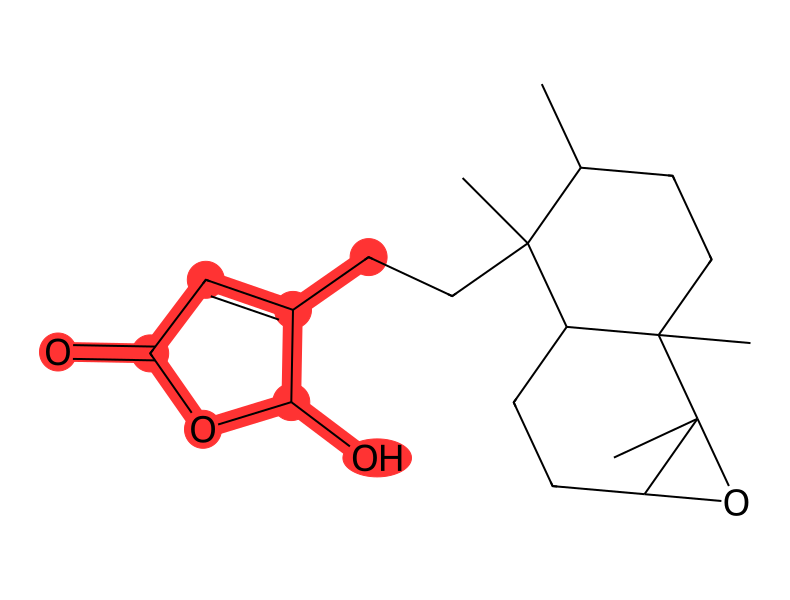

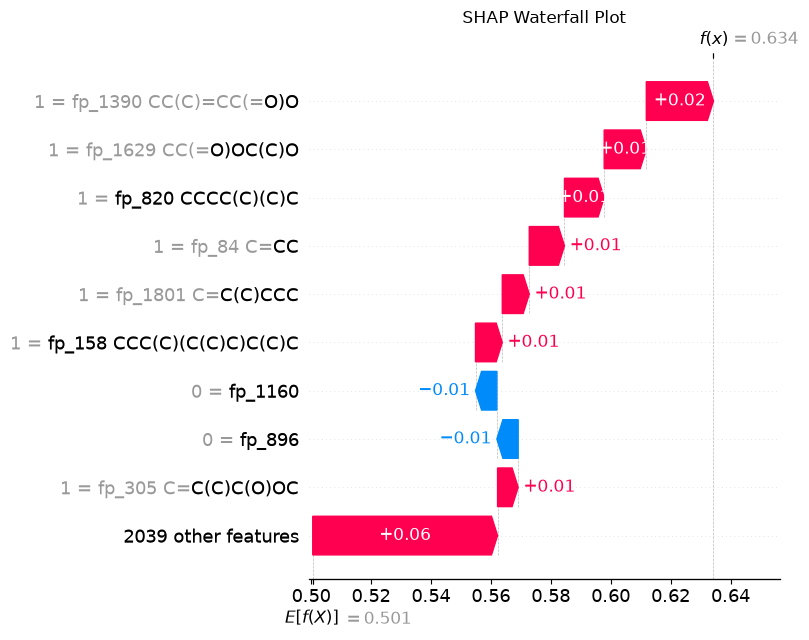


##### CNP0248457.1 | nan | model probability: 0.616
SMILES: CC1=CCCC2C1(C(=O)O)CCC(C)C2(C)CCC1=CC(=O)OC1O
Base value: 0.501 | Model probability: 0.616
=== Overlaying Top 2 Present Features ===
Bit ID: 1390| SHAP: +0.020047| Active (+)
Bit ID:  820| SHAP: +0.014337| Active (+)


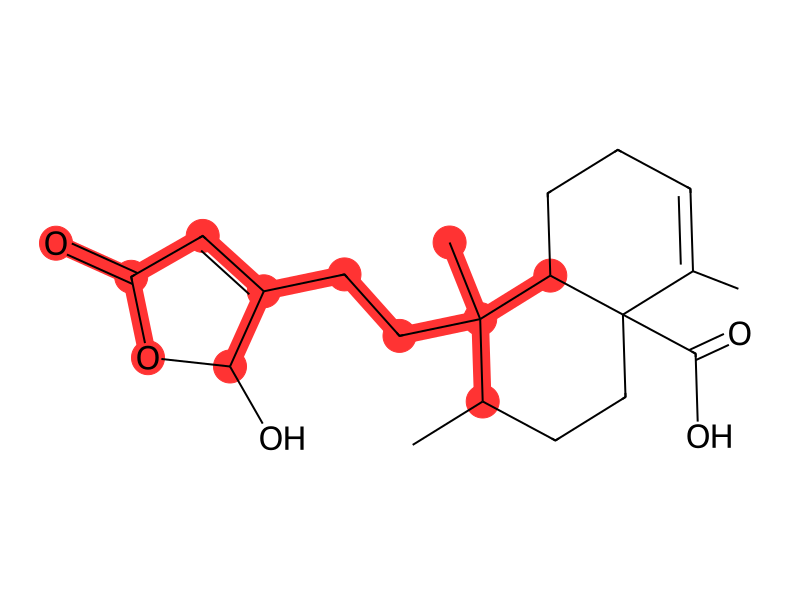

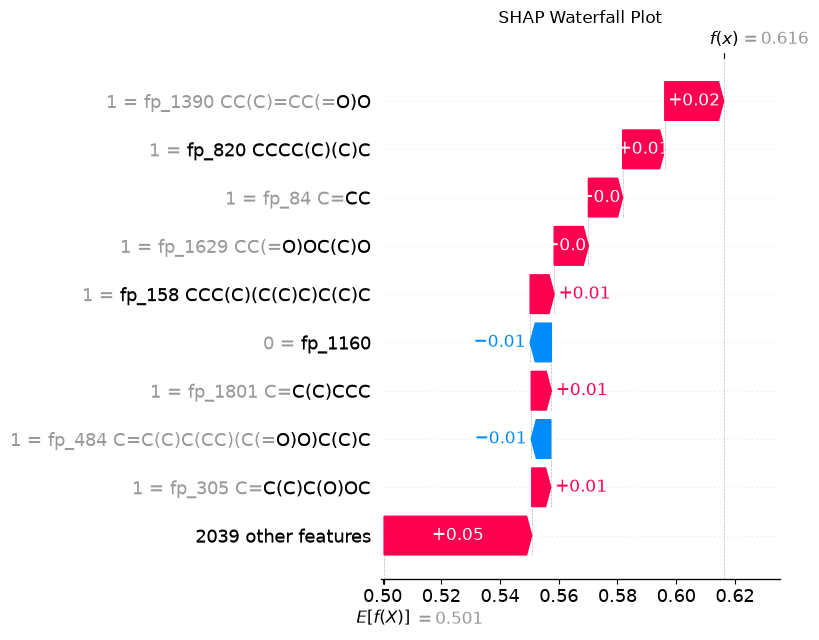


##### CNP0202396.4 | nan | model probability: 0.611
SMILES: CC1CCC2(C)C(C(=O)O)=CCCC2C1(C)CCC1=CC(=O)OC1O
Base value: 0.501 | Model probability: 0.611
=== Overlaying Top 2 Present Features ===
Bit ID: 1390| SHAP: +0.020179| Active (+)
Bit ID: 1629| SHAP: +0.014194| Active (+)


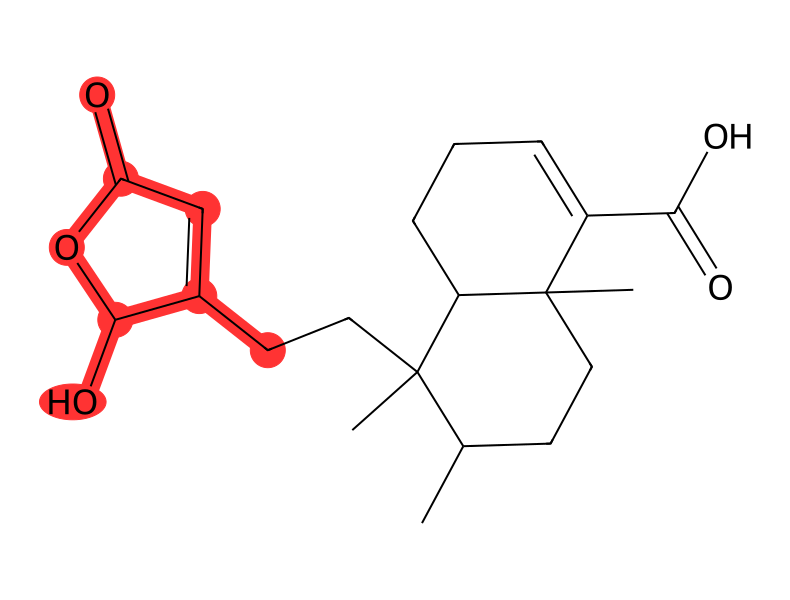

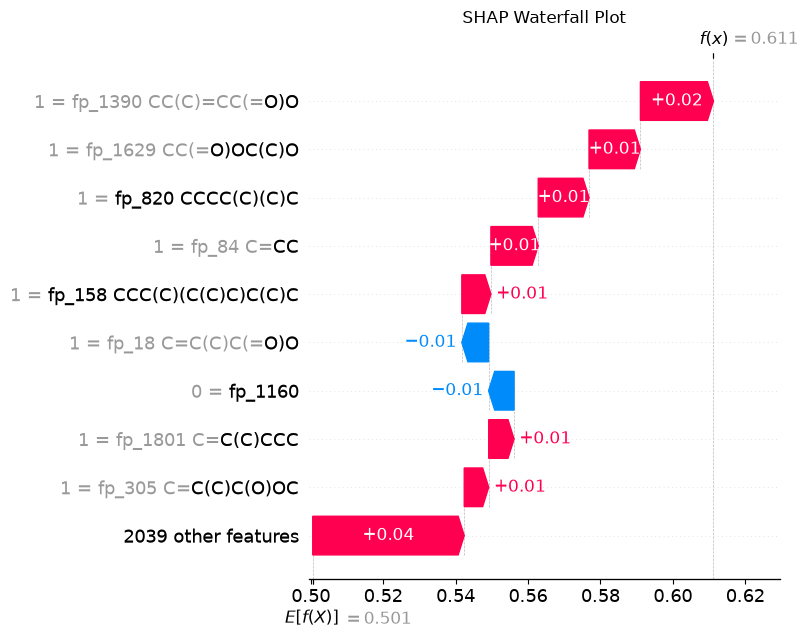


##### CNP0261728.1 | (2S)-3-[2-[(1S,2R,4aR,6S,8aR)-4a,6-dihydroxy-1,2,5,5-tetramethyl-3,4,6,7,8,8a-hexahydro-2H-naphthalen-1-yl]ethyl]-2-hydroxy-2H-furan-5-one | model probability: 0.599
SMILES: CC1CCC2(O)C(CCC(O)C2(C)C)C1(C)CCC1=CC(=O)OC1O
Base value: 0.501 | Model probability: 0.599
=== Overlaying Top 2 Present Features ===
Bit ID: 1390| SHAP: +0.023228| Active (+)
Bit ID: 1629| SHAP: +0.014441| Active (+)


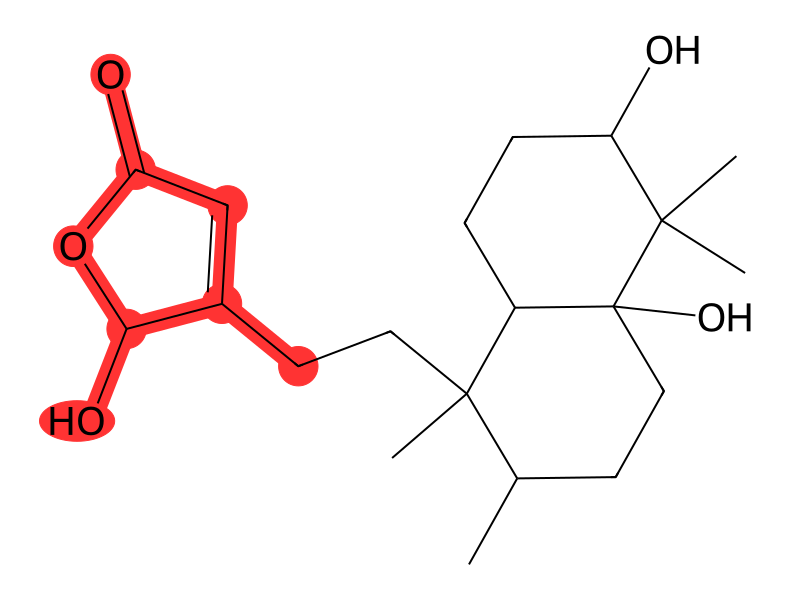

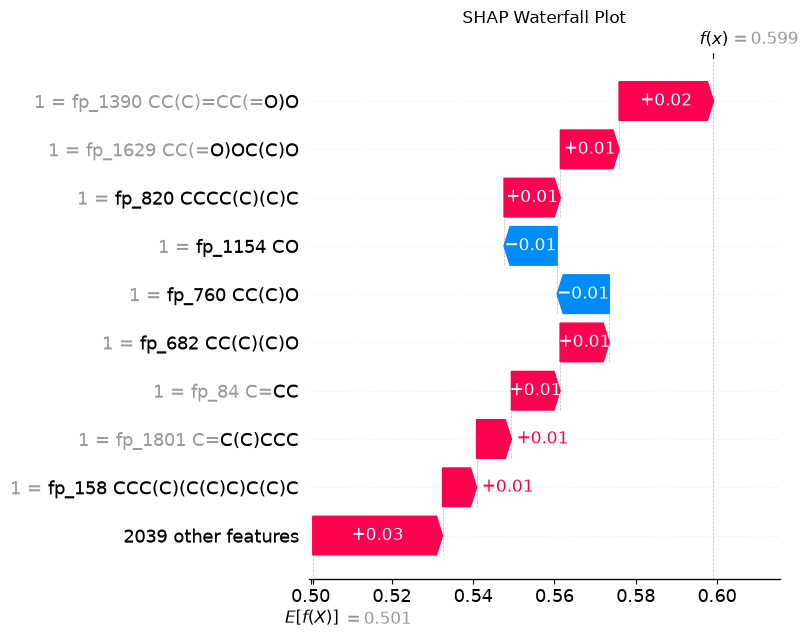


##### CNP0305248.1 | (2R)-3-[2-[(1S,2R,5S,8aR)-5-hydroxy-1,2,4a,5-tetramethyl-3,4,6,7,8,8a-hexahydro-2H-naphthalen-1-yl]ethyl]-2-hydroxy-2H-furan-5-one | model probability: 0.599
SMILES: CC1CCC2(C)C(CCCC2(C)O)C1(C)CCC1=CC(=O)OC1O
Base value: 0.501 | Model probability: 0.599
=== Overlaying Top 2 Present Features ===
Bit ID: 1390| SHAP: +0.022810| Active (+)
Bit ID: 1629| SHAP: +0.014250| Active (+)


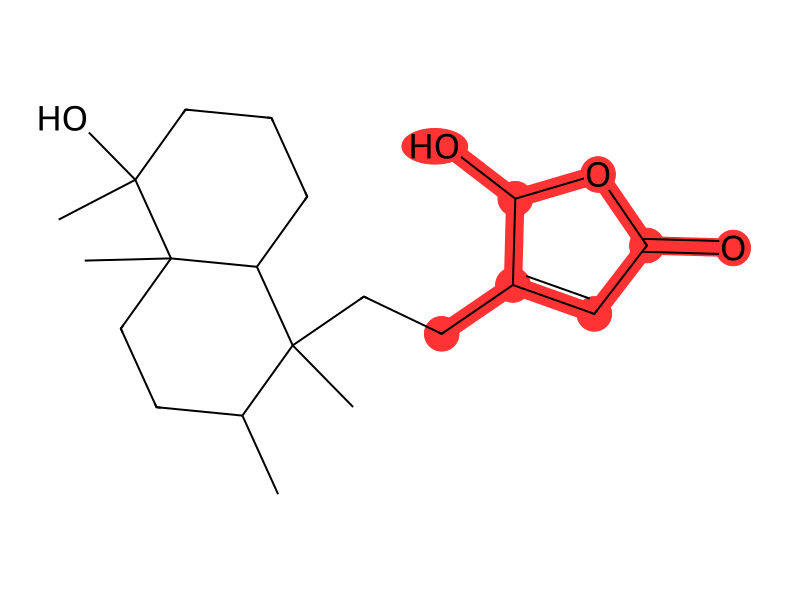

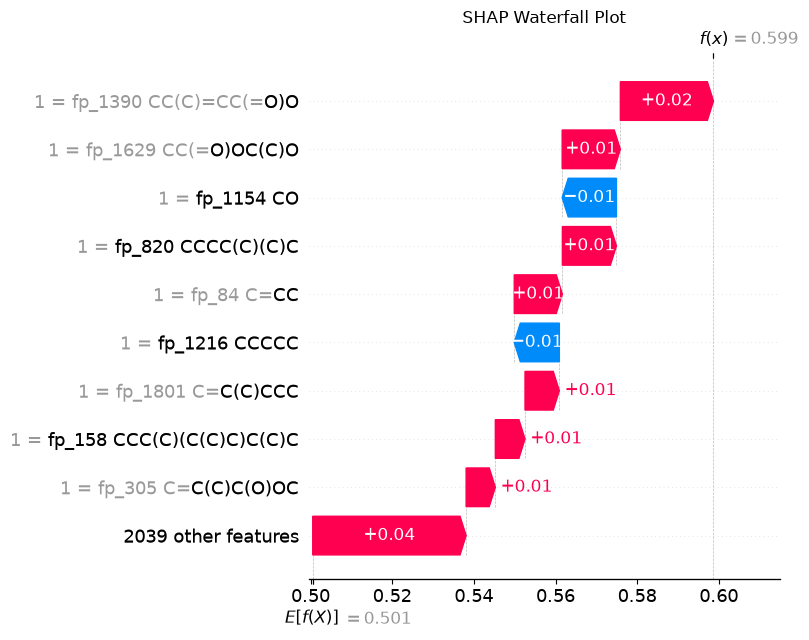


##### CNP0232267.1 | 16-Hydroxy-2-oxocleroda-3,13-dien-15,16-olide | model probability: 0.591
SMILES: CC1=CC(=O)CC2C1(C)CCC(C)C2(C)CCC1=CC(=O)OC1O
Base value: 0.501 | Model probability: 0.591
=== Overlaying Top 2 Present Features ===
Bit ID: 1390| SHAP: +0.020774| Active (+)
Bit ID:  820| SHAP: +0.015135| Active (+)


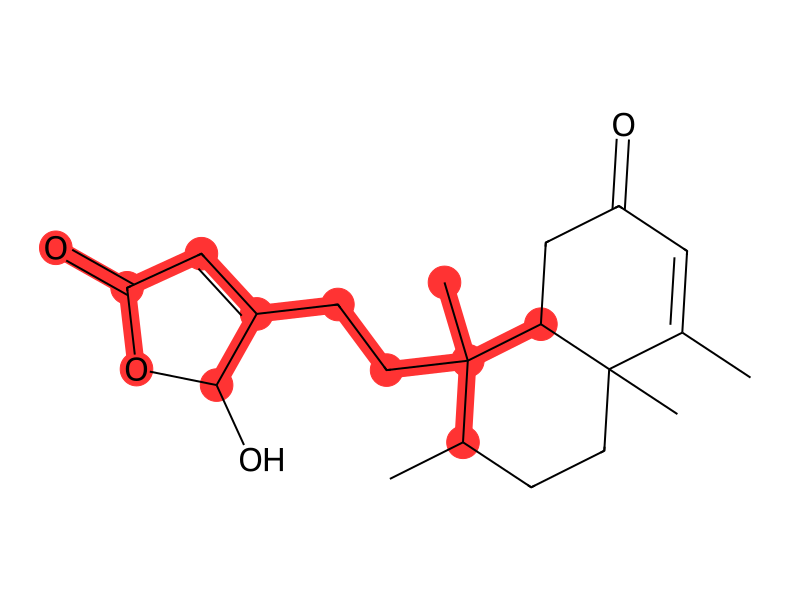

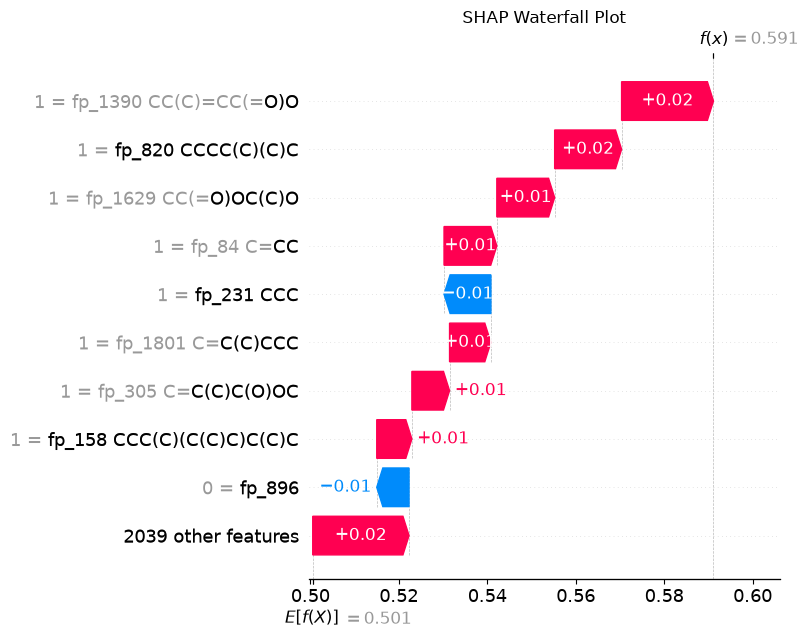


##### CNP0174086.1 | nan | model probability: 0.569
SMILES: CC1CCC2(C)C(CCC(O)C2(C)O)C1(C)CCC1=CC(=O)OC1O
Base value: 0.501 | Model probability: 0.569
=== Overlaying Top 2 Present Features ===
Bit ID: 1390| SHAP: +0.024481| Active (+)
Bit ID:  479| SHAP: -0.018235| Inactive (-)


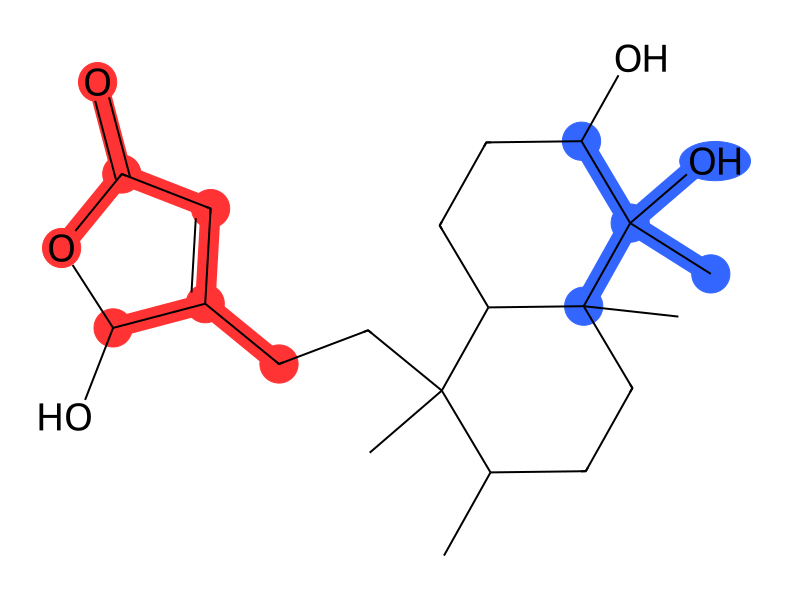

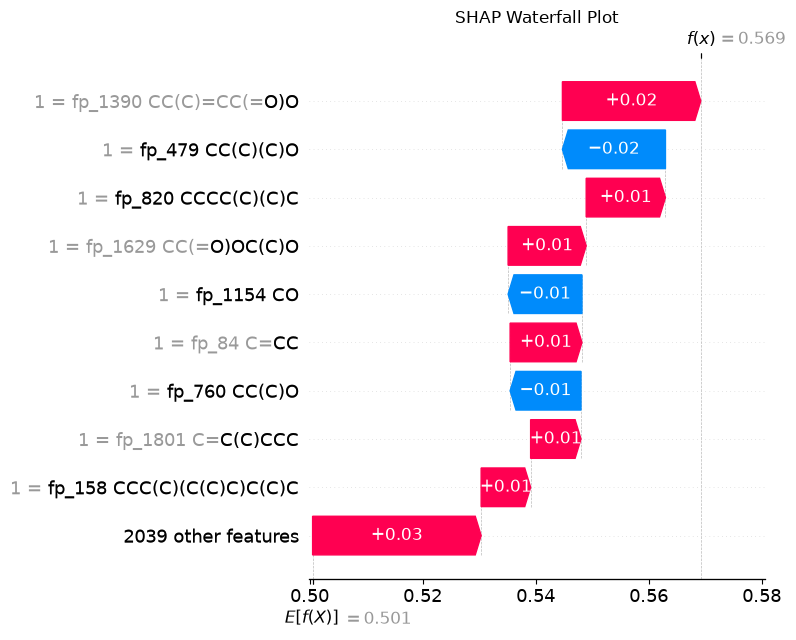


##### CNP0262123.1 | 3-[2-[(1S,2R,4aR,5S,8aR)-1,2,4a,5-tetramethyl-6-oxo-3,4,5,7,8,8a-hexahydro-2H-naphthalen-1-yl]ethyl]-2-hydroxy-2H-furan-5-one | model probability: 0.560
SMILES: CC1CCC2(C)C(C)C(=O)CCC2C1(C)CCC1=CC(=O)OC1O
Base value: 0.501 | Model probability: 0.560
=== Overlaying Top 2 Present Features ===
Bit ID:  104| SHAP: -0.028878| Inactive (-)
Bit ID: 1390| SHAP: +0.020652| Active (+)


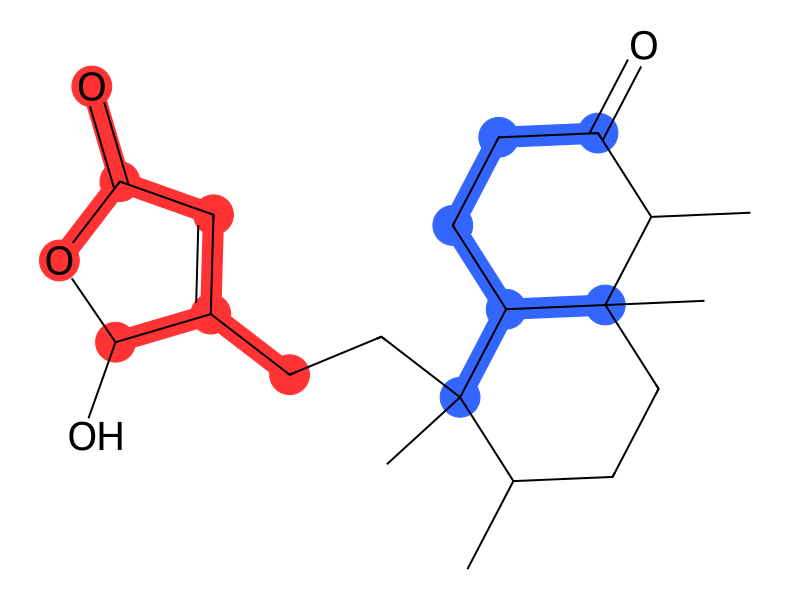

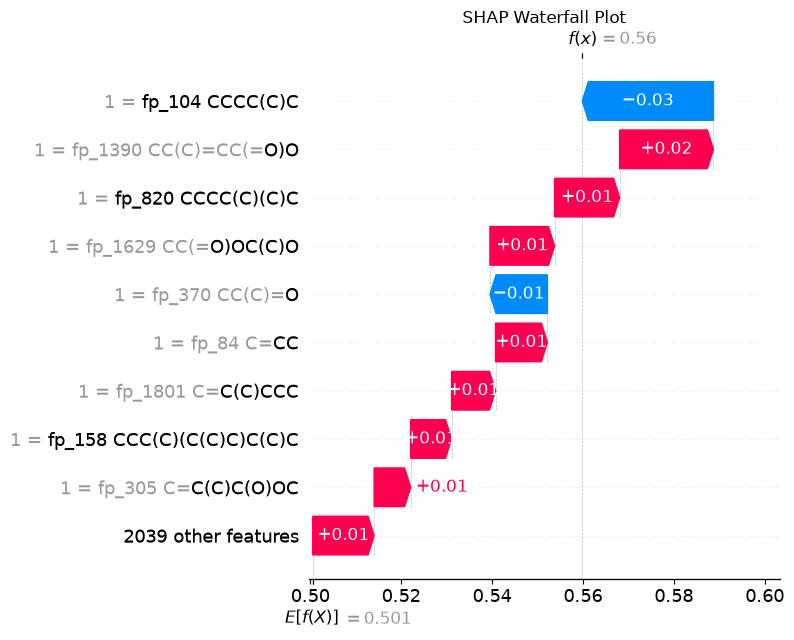


##### CNP0185502.1 | 16-Oxocleroda-3,13E-dien-15-oic acid | model probability: 0.552
SMILES: CC1=CCCC2C1(C)CCC(C)C2(C)CCC(C=O)=CC(=O)O
Base value: 0.501 | Model probability: 0.552
=== Overlaying Top 2 Present Features ===
Bit ID:  872| SHAP: +0.009479| Active (+)
Bit ID: 2029| SHAP: +0.008604| Active (+)


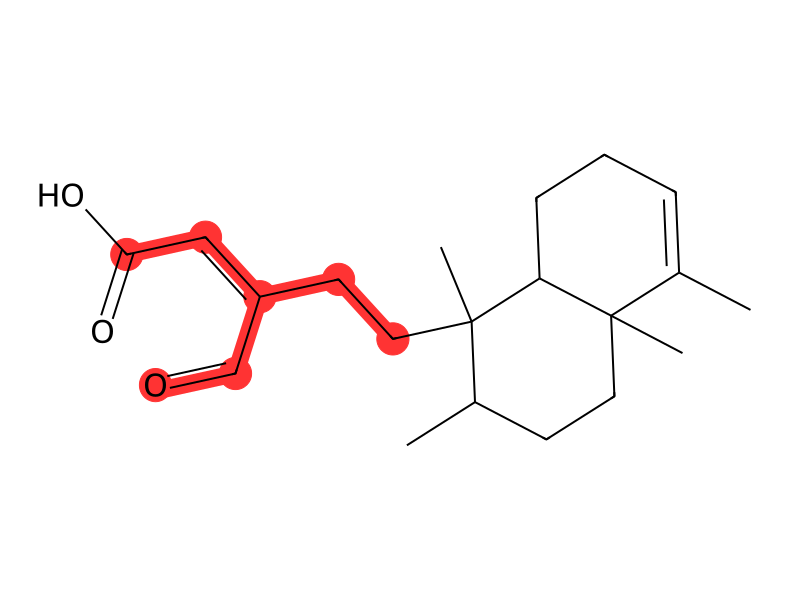

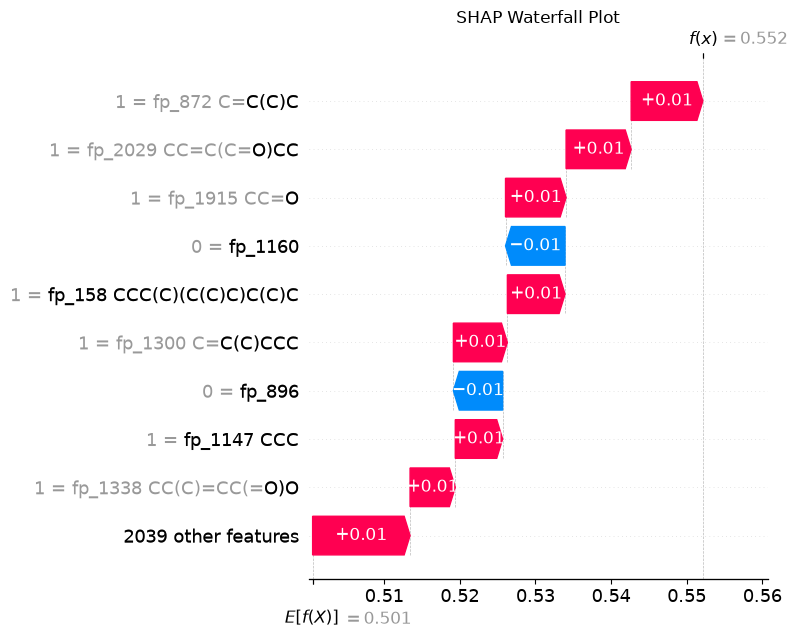


##### CNP0260692.3 | [3-[2-[(1S,2R,4aR,8aR)-1,2,4a,5-tetramethyl-2,3,4,7,8,8a-hexahydronaphthalen-1-yl]ethyl]-5-oxo-2H-furan-2-yl] acetate | model probability: 0.549
SMILES: CC(=O)OC1OC(=O)C=C1CCC1(C)C(C)CCC2(C)C(C)=CCCC21
Base value: 0.501 | Model probability: 0.549
=== Overlaying Top 2 Present Features ===
Bit ID: 1390| SHAP: +0.019541| Active (+)
Bit ID:  820| SHAP: +0.013570| Active (+)


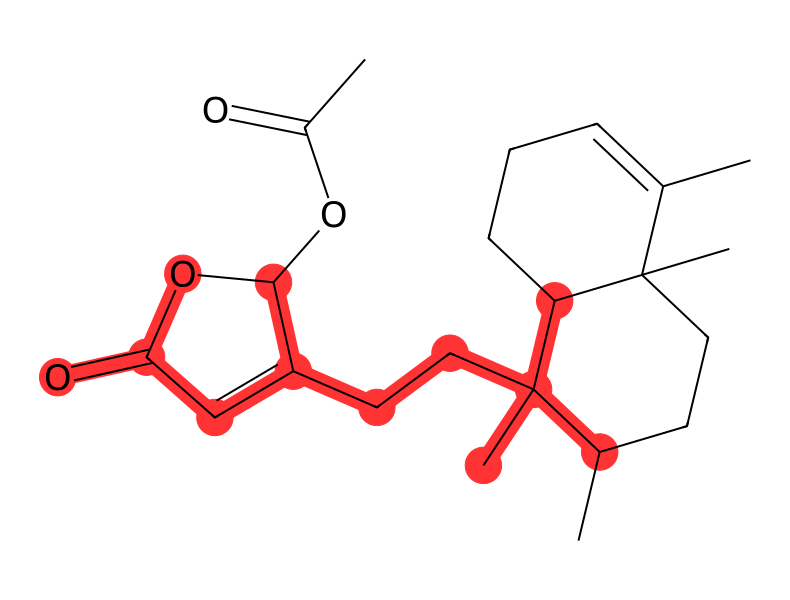

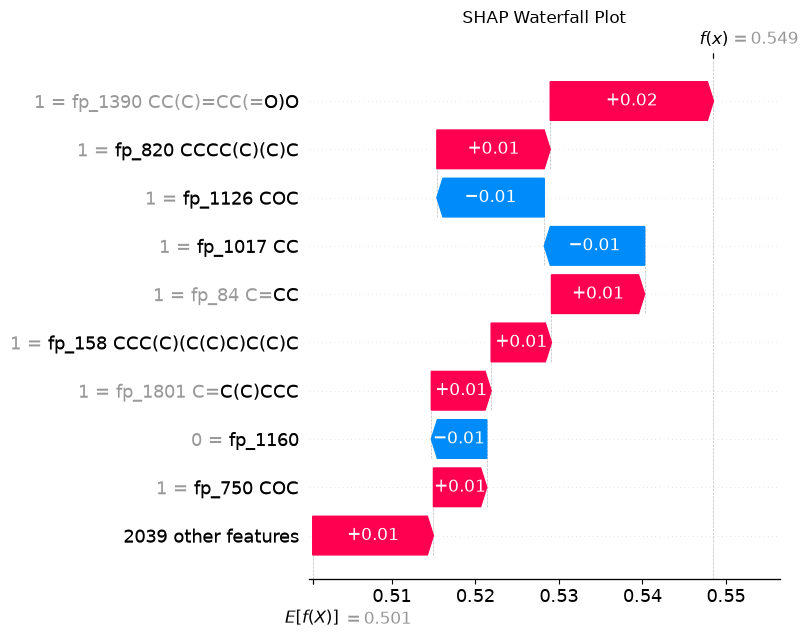

In [25]:
import ethnohack.explainer as xai

model = cox.load_model()
top = hits.head(COCONUT_N_EXPLAIN)

# fingerprint bits get a substructure hint in their name for the plots
coconut_names = xai.readable_feature_names(cox.feature_names(), top["std_smiles"])

for _, row in top.iterrows():
    print(f"\n##### {row['id']} | {row['name']} | model probability: {row['proba']:.3f}")
    xai.explain_molecule(
        row["std_smiles"],
        model,
        target_class=TARGET_CLASS,
        feature_names=coconut_names,
        featurizer=cox.featurize,
    )